<a href="https://colab.research.google.com/github/sousadeoliveiragabriella19-droid/Atividade4NeuroStartup/blob/main/classificador_roupas_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Conhecendo os dados

**Problema:** uma loja online precisa cadastrar muitas fotos de roupas e hoje escolhe a categoria de cada uma na mão. A ideia é treinar um modelo que olha a foto e diz qual é a peça (10 categorias possíveis).

Vamos usar o Fashion-MNIST, que tem 70 mil fotos 28x28 em preto e branco. Para medir, usamos a acurácia (% de acertos).

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from ipywidgets import interact

SEED = 42
keras.utils.set_random_seed(SEED)

CLASSES = ["Camiseta/top", "Calça", "Pulôver", "Vestido", "Casaco",
           "Sandália", "Camisa", "Tênis", "Bolsa", "Bota"]

O dataset já vem separado em treino e teste, mas juntamos tudo para fazer a nossa própria divisão depois.

In [17]:
(x_a, y_a), (x_b, y_b) = keras.datasets.fashion_mnist.load_data()
X = np.concatenate([x_a, x_b])
y = np.concatenate([y_a, y_b])
print("Fotos:", X.shape)
print("Respostas:", y.shape)

Fotos: (70000, 28, 28)
Respostas: (70000,)


### Gráfico 1 - quantidade de fotos por categoria

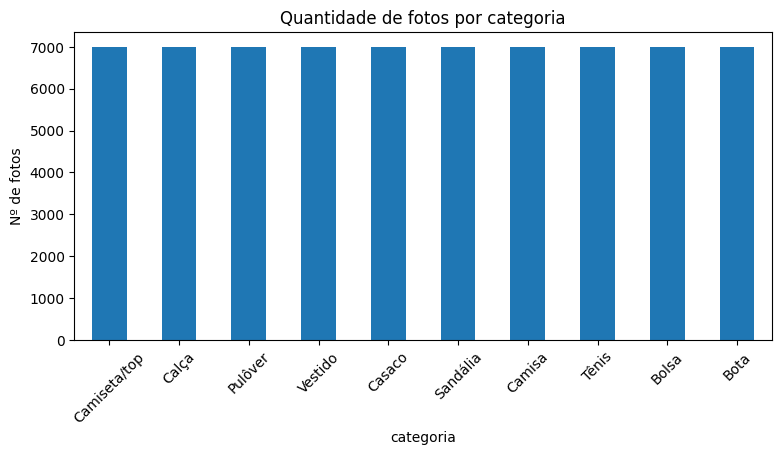

In [18]:
df = pd.DataFrame({"categoria": [CLASSES[i] for i in y]})
contagem = df["categoria"].value_counts().reindex(CLASSES)

contagem.plot(kind="bar", figsize=(9, 4))
plt.title("Quantidade de fotos por categoria")
plt.ylabel("Nº de fotos")
plt.xticks(rotation=45)
plt.show()

**Conclusão:** todas as categorias têm 7.000 fotos, então os dados estão equilibrados. Por isso a acurácia é uma boa métrica. Se o modelo chutasse sempre a mesma categoria, acertaria só 10%.

### Gráfico 2 - foto média de cada categoria
Tiramos a média de todas as fotos de cada categoria para ver o formato típico.

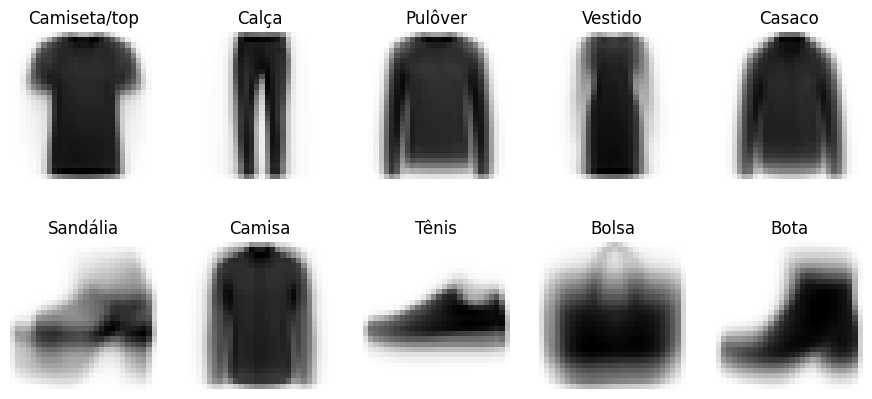

In [19]:
fig, eixos = plt.subplots(2, 5, figsize=(11, 5))
for c, ax in enumerate(eixos.flat):
    ax.imshow(X[y == c].mean(axis=0), cmap="gray_r")
    ax.set_title(CLASSES[c])
    ax.axis("off")
plt.show()

**Conclusão:** calça, bolsa e os calçados têm formatos bem diferentes, então devem ser fáceis. Já camiseta, pulôver, camisa e casaco têm médias muito parecidas, então achamos que o modelo vai confundir essas.

### Preparando e separando os dados
Dividimos os pixels por 255 para ficarem entre 0 e 1 (dica do professor, no lugar do StandardScaler).

Depois separamos em:
- **treino (60%)**: para o modelo aprender
- **validação (20%)**: para comparar os modelos
- **teste (20%)**: o "cofre", só usamos uma vez no final

O `stratify` deixa a mesma proporção de cada categoria em todos os grupos.

In [20]:
X = X.astype("float32") / 255.0

X_resto, X_teste, y_resto, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
X_treino, X_valid, y_treino, y_valid = train_test_split(
    X_resto, y_resto, test_size=0.25, random_state=SEED, stratify=y_resto)

print("Treino:", len(X_treino), "| Validação:", len(X_valid), "| Teste:", len(X_teste))

# o scikit-learn precisa das fotos "achatadas" (28x28 = 784 colunas)
X_treino_v = X_treino.reshape(len(X_treino), -1)
X_valid_v = X_valid.reshape(len(X_valid), -1)
X_teste_v = X_teste.reshape(len(X_teste), -1)

Treino: 42000 | Validação: 14000 | Teste: 14000


## 2. Baseline x Rede neural

### Baseline
Primeiro um modelo simples para ter uma base de comparação: a regressão logística (Aula 05). Também testamos uma árvore de decisão (bônus).

In [21]:
baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_treino_v, y_treino)
acc_base_valid = accuracy_score(y_valid, baseline.predict(X_valid_v))

arvore = DecisionTreeClassifier(max_depth=15, random_state=SEED)
arvore.fit(X_treino_v, y_treino)
acc_arv_valid = accuracy_score(y_valid, arvore.predict(X_valid_v))

print(f"Regressão logística - validação: {acc_base_valid:.1%}")
print(f"Árvore de decisão   - validação: {acc_arv_valid:.1%}")

Regressão logística - validação: 85.2%
Árvore de decisão   - validação: 80.5%


### Rede neural (Keras)
A rede tem:
- `Flatten`: transforma a foto 28x28 em 784 números
- `Dense` com `relu`: camada escondida que aprende os padrões
- `Dropout`: desliga alguns neurônios no treino para a rede não decorar
- `Dense(10, softmax)`: saída com a probabilidade de cada categoria

Fizemos uma função para criar a rede, assim dá para testar vários tamanhos.

In [22]:
def criar_rede(neuronios, dropout):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(neuronios, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(optimizer="adam",
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modelo

### Experimentos
Testamos 3 redes diferentes e salvamos os resultados no `experimentos.csv`.

Usamos **early stopping**: o treino para sozinho quando a perda na validação não melhora por 3 épocas, e a rede volta para os melhores pesos. Assim ela não fica decorando o treino.

In [8]:
tentativas = [(64, 0.0), (128, 0.2), (256, 0.3)]
resultados = []
redes = []
historicos = []

for neuronios, dropout in tentativas:
    rede = criar_rede(neuronios, dropout)
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    hist = rede.fit(X_treino, y_treino, validation_data=(X_valid, y_valid),
                    epochs=30, batch_size=128, callbacks=[parada], verbose=0)
    acc = rede.evaluate(X_valid, y_valid, verbose=0)[1]
    print(f"{neuronios} neurônios, dropout {dropout}: {acc:.1%} ({len(hist.history['loss'])} épocas)")

    resultados.append({"neuronios": neuronios, "dropout": dropout,
                       "epocas": len(hist.history["loss"]), "acc_valid": round(acc, 4)})
    redes.append(rede)
    historicos.append(hist)

experimentos = pd.DataFrame(resultados)
experimentos.to_csv("experimentos.csv", index=False)
experimentos

64 neurônios, dropout 0.0: 87.9% (20 épocas)
128 neurônios, dropout 0.2: 88.6% (18 épocas)
256 neurônios, dropout 0.3: 88.7% (18 épocas)


,neuronios,dropout,epocas,acc_valid
0,64,0.0,20,0.8794
1,128,0.2,18,0.8857
2,256,0.3,18,0.8869


Escolhemos a rede com maior acurácia na validação.

In [9]:
melhor = experimentos["acc_valid"].idxmax()
melhor_rede = redes[melhor]
acc_rede_valid = experimentos["acc_valid"][melhor]
print("Melhor rede:", tentativas[melhor], "-", f"{acc_rede_valid:.1%}")

Melhor rede: (256, 0.3) - 88.7%


### Curvas de aprendizado

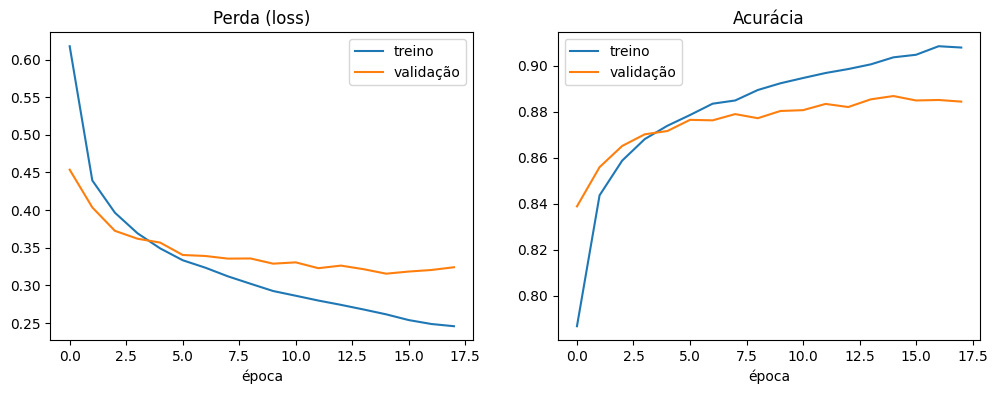

In [10]:
h = historicos[melhor].history

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(h["loss"], label="treino")
plt.plot(h["val_loss"], label="validação")
plt.title("Perda (loss)")
plt.xlabel("época")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h["accuracy"], label="treino")
plt.plot(h["val_accuracy"], label="validação")
plt.title("Acurácia")
plt.xlabel("época")
plt.legend()
plt.show()

**Conclusão:** _(ajustar com o gráfico)_ no começo treino e validação melhoram juntos. Depois de algumas épocas a perda da validação para de cair enquanto a do treino continua caindo, sinal de que a rede começaria a decorar. Aí o early stopping parou o treino.

## 3. Abrindo o cofre
Agora que já escolhemos o modelo, usamos o teste uma única vez.

In [11]:
acc_base_teste = accuracy_score(y_teste, baseline.predict(X_teste_v))
acc_arv_teste = accuracy_score(y_teste, arvore.predict(X_teste_v))
pred_rede = melhor_rede.predict(X_teste, verbose=0).argmax(axis=1)
acc_rede_teste = accuracy_score(y_teste, pred_rede)

print(f"Regressão logística - teste: {acc_base_teste:.1%}")
print(f"Árvore de decisão   - teste: {acc_arv_teste:.1%}")
print(f"Rede neural         - teste: {acc_rede_teste:.1%}")

Regressão logística - teste: 84.5%
Árvore de decisão   - teste: 80.9%
Rede neural         - teste: 89.0%


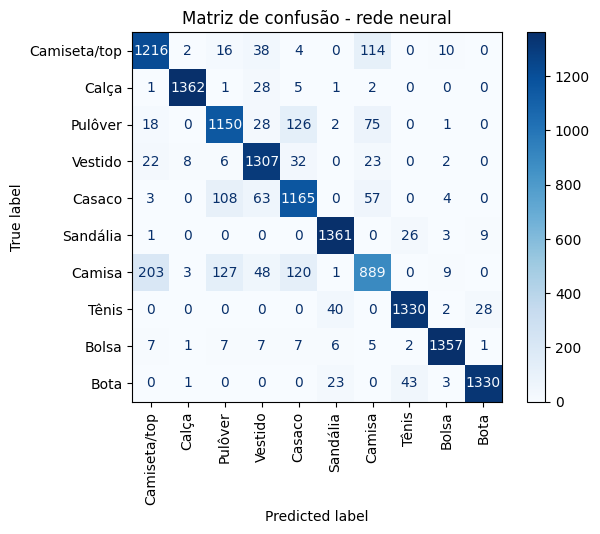

In [12]:
ConfusionMatrixDisplay.from_predictions(y_teste, pred_rede, display_labels=CLASSES,
                                        xticks_rotation=90, cmap="Blues")
plt.title("Matriz de confusão - rede neural")
plt.show()

In [13]:
acertos_rede = round(acc_rede_teste * 1000)
acertos_base = round(acc_base_teste * 1000)
print(f"A cada 1000 produtos, a rede acerta {acertos_rede} e o modelo simples acerta {acertos_base}.")
print(f"São {acertos_rede - acertos_base} produtos a menos para corrigir na mão.")

A cada 1000 produtos, a rede acerta 890 e o modelo simples acerta 845.
São 45 produtos a menos para corrigir na mão.


**Frase de negócio:** _(preencher com os números de cima)_ "A cada 1000 produtos cadastrados, nosso modelo acerta ___ sozinho, contra ___ do modelo simples. As peças de cima (camisa, camiseta, pulôver) são as que ele mais erra, como a gente esperava pela foto média."

## 4. Produto
Salvamos o modelo para usar depois sem precisar treinar de novo.

In [14]:
melhor_rede.save("modelo_fashion.keras")
modelo = keras.models.load_model("modelo_fashion.keras")
print("Modelo salvo e carregado!")

Modelo salvo e carregado!


### Tela
Escolha o número de uma foto do teste e veja o que o modelo acha que é.

In [25]:
def classificar(indice):
    foto = X_teste[indice]
    probs = modelo.predict(foto.reshape(1, 28, 28), verbose=0)[0]
    palpite = probs.argmax()

    plt.imshow(foto, cmap="gray_r")
    plt.title(f"Real: {CLASSES[y_teste[indice]]}  |  Modelo: {CLASSES[palpite]} ({probs[palpite]:.0%})")
    plt.axis("off")
    plt.show()

interact(classificar, indice=(0, len(X_teste) - 1));

interactive(children=(IntSlider(value=6999, description='indice', max=13999), Output()), _dom_classes=('widget…